# Can an algorithm find cancer types without being told? k-means vs hierarchical clustering

**Module 03.1 · my implementation**, Seid Adem

The [dimensionality-reduction notebook](02_tcga_dimensionality_reduction.ipynb) showed that the 12 cancer types form
visible groups. Here the labels are hidden from the algorithms: **can clustering rediscover the types, and can we
tell from the data alone how many groups there are?**

> **New to clustering?** Clustering means grouping samples by similarity **without** labels
> ([Lesson 6](../LESSONS.md#lesson-6--a-tour-of-the-algorithm-families)). Two scores are used throughout:
> * **Silhouette** (−1 to 1) uses **no labels**. For each sample it compares the distance to its own cluster with the
>   distance to the nearest other cluster; higher means tighter, better-separated clusters. It is what you would
>   have in a real discovery project.
> * **Adjusted Rand index (ARI)** (about 0 = random, 1 = perfect) compares clusters with the **known** cancer types.
>   It's only available here because this is a benchmark with known answers.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyreadr
import seaborn as sns
import umap
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler

from dsls.expression import balanced_subsample, tcga_sample_type, top_variable_genes

FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
# umap-learn warns that a fixed random_state disables parallelism; that is intended here (reproducibility)
warnings.filterwarnings("ignore", message="n_jobs value", category=UserWarning)

## 1 · Same data, same label-free preprocessing

Identical to the previous notebook (same seed, so the same 720 tumours): 2,000 most variable genes → standardise →
50 principal components. Clustering runs on the 50 PCs.

In [2]:
DATA = Path("../../../data/raw/gene_expression")
SEED = 0

# 12 cancer types: 8 that come in biologically related pairs, plus 4 unrelated ones
TYPES = {
    "lung adenocarcinoma": "LUAD", "lung squamous cell carcinoma": "LUSC",
    "kidney clear cell carcinoma": "KIRC", "kidney papillary cell carcinoma": "KIRP",
    "brain lower grade glioma": "LGG", "glioblastoma multiforme": "GBM",
    "colon adenocarcinoma": "COAD", "rectum adenocarcinoma": "READ",
    "breast invasive carcinoma": "BRCA", "prostate adenocarcinoma": "PRAD",
    "thyroid carcinoma": "THCA", "liver hepatocellular carcinoma": "LIHC",
}  # fmt: skip
ORDER = list(TYPES.values())
PALETTE = dict(zip(ORDER, sns.color_palette("Paired", 12), strict=True))  # related pairs share a hue

expr_all = pyreadr.read_r(DATA / "pan_cancer_dataset.RDS")[None].set_index("gene").T  # samples × genes
labels_all = pd.read_csv(DATA / "labels.tsv", sep="\t").set_index("sample")["_primary_disease"]
assert expr_all.index.is_unique and expr_all.columns.is_unique
assert set(expr_all.index) <= set(labels_all.index), "every expression sample has a label"

primary = [s for s in expr_all.index if tcga_sample_type(s) == "01"]  # primary tumours only
labels = labels_all.loc[primary]
labels = labels[labels.isin(TYPES)].map(TYPES)
subset = balanced_subsample(labels, n_per_class=60, seed=SEED)
expr = expr_all.loc[subset.index]
y = subset.to_numpy()

print(f"full matrix: {expr_all.shape[0]:,} samples × {expr_all.shape[1]:,} genes")
print(f"primary tumours of the 12 types: {len(labels):,}; balanced subset: {len(subset)} (60 per type)")

full matrix: 10,459 samples × 20,530 genes
primary tumours of the 12 types: 5,360; balanced subset: 720 (60 per type)


In [3]:
genes = top_variable_genes(expr, 2000)
P = PCA(n_components=50, random_state=SEED).fit_transform(StandardScaler().fit_transform(expr[genes]))
P.shape

(720, 50)

## 2 · The algorithms

> **In plain language.**
> * **k-means:** you choose *k*. It places *k* centres, assigns each sample to the nearest centre, moves each centre
>   to the middle of its samples, and repeats. It prefers round clusters of similar size, and the result depends on
>   the random starting centres (so it is run 20 times and the best run kept: `n_init=20`).
> * **Hierarchical (agglomerative):** start with every sample alone and repeatedly **merge the two closest groups**.
>   The result is a tree (a *dendrogram*); cutting it at a chosen height gives *k* clusters. "Closest" needs a rule,
>   called the **linkage**:
>
> | Linkage | Distance between two groups | Tendency |
> |---------|-----------------------------|----------|
> | Ward | how much merging increases within-group spread | compact, similar-sized clusters (like k-means) |
> | Average | mean distance between all pairs | in between |
> | Complete | distance between the two *farthest* members | compact, but sensitive to outliers |
>
> It is deterministic (no random start), and the tree itself is informative.

Every method is run for every *k* from 2 to 20 and scored with both silhouette and ARI.

In [4]:
methods = {
    "k-means": lambda k: KMeans(n_clusters=k, n_init=20, random_state=SEED),
    "hierarchical (Ward)": lambda k: AgglomerativeClustering(n_clusters=k, linkage="ward"),
    "hierarchical (average)": lambda k: AgglomerativeClustering(n_clusters=k, linkage="average"),
    "hierarchical (complete)": lambda k: AgglomerativeClustering(n_clusters=k, linkage="complete"),
}
rows = []
for k in range(2, 21):
    for name, make in methods.items():
        found = make(k).fit_predict(P)
        rows.append(
            {
                "k": k,
                "method": name,
                "silhouette": silhouette_score(P, found),
                "ARI": adjusted_rand_score(y, found),
            }
        )
sweep = pd.DataFrame(rows)

best = sweep.loc[sweep.groupby("method")["silhouette"].idxmax()].set_index("method")
best_ari = sweep.loc[sweep.groupby("method")["ARI"].idxmax()].set_index("method")
pd.DataFrame(
    {
        "k chosen by silhouette": best["k"],
        "ARI at that k": best["ARI"],
        "ARI at k = 12": sweep[sweep.k == 12].set_index("method")["ARI"],
        "best possible ARI": best_ari["ARI"],
        "k with best ARI": best_ari["k"],
    }
).round(3)

,k chosen by silhouette,ARI at that k,ARI at k = 12,best possible ARI,k with best ARI
method,,,,,
hierarchical (Ward),9,0.728,0.817,0.817,12
hierarchical (average),11,0.702,0.705,0.782,19
hierarchical (complete),6,0.469,0.715,0.726,20
k-means,9,0.745,0.824,0.848,11


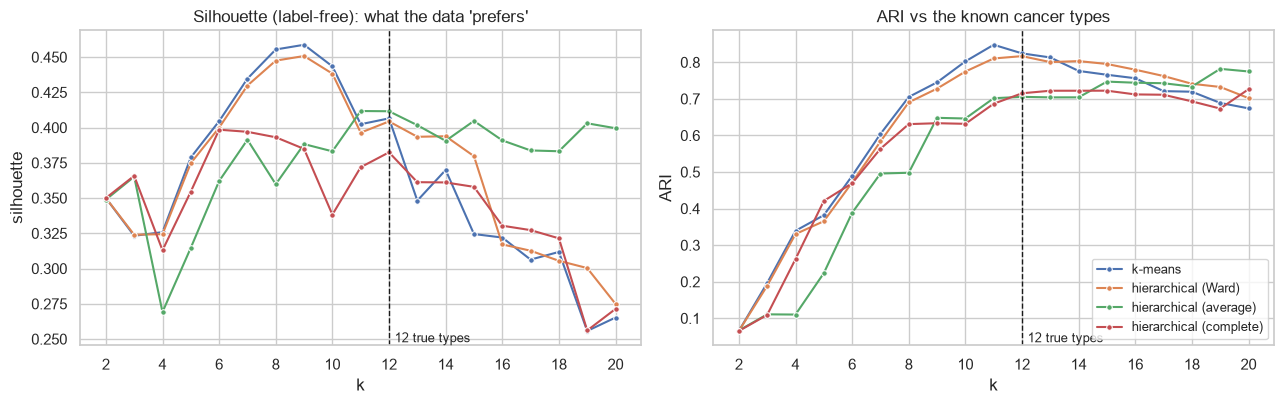

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharex=True)
for ax, metric in zip(axes, ["silhouette", "ARI"], strict=True):
    sns.lineplot(
        data=sweep, x="k", y=metric, hue="method", marker="o", markersize=4, ax=ax, legend=metric == "ARI"
    )
    ax.axvline(12, color="k", ls="--", lw=1)
    ax.text(12.2, ax.get_ylim()[0], "12 true types", fontsize=9, va="bottom")
axes[0].set_title("Silhouette (label-free): what the data 'prefers'")
axes[1].set_title("ARI vs the known cancer types")
axes[1].legend(title="", fontsize=9, loc="lower right")
axes[1].set_xticks(range(2, 21, 2))
fig.tight_layout()
fig.savefig(FIGURES / "09_k_sweep.png", dpi=150)
plt.show()

**Reading the curves**

* **The label-free silhouette peaks at k = 9** for both k-means and Ward, not at the 12 true types. Taken alone, it
  would tell a researcher "there are about 9 groups".
* **Agreement with the true types (ARI) peaks at k = 11–12** (k-means 0.85 at k = 11; Ward 0.82 at k = 12).
* **k-means and Ward behave almost identically**: both look for compact, round groups. **Average and complete
  linkage are clearly worse** here (best ARI 0.78 and 0.73, reached only at k = 19–20), because they tend to split
  off small outlying groups instead of balanced ones.

So is the silhouette "wrong" to choose 9? The contingency tables answer that.

## 3 · What the clusters contain

> **In plain language.** A **contingency table** crosses the found clusters (columns) with the true types (rows).
> A perfect result has one dark cell per row and per column.

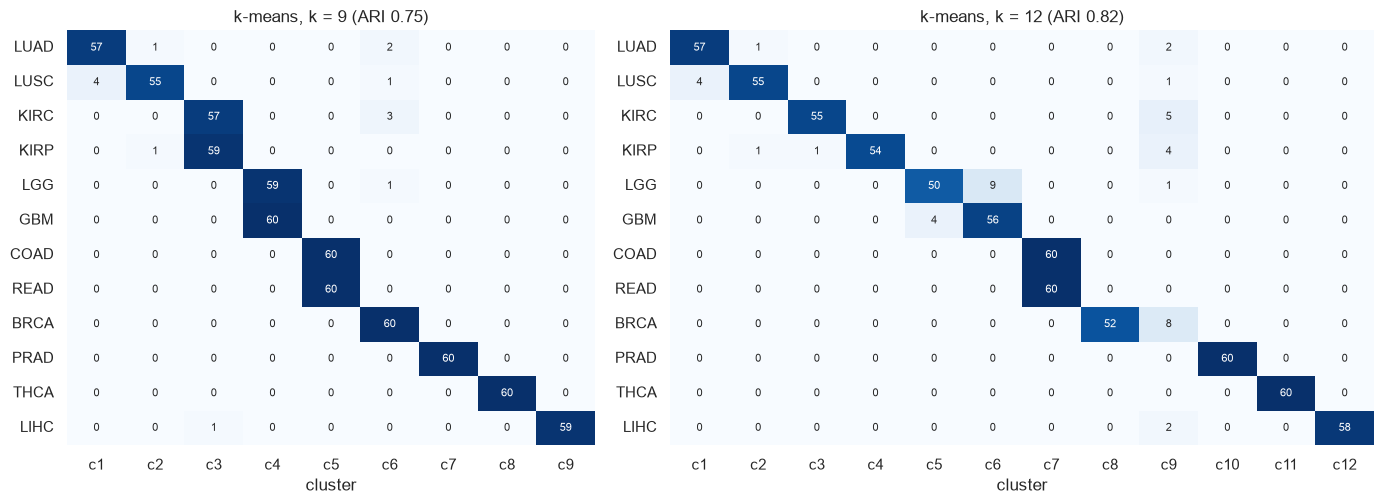

In [6]:
k_sil = int(best.loc["k-means", "k"])
found = {k: KMeans(n_clusters=k, n_init=20, random_state=SEED).fit_predict(P) for k in (k_sil, 12)}

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [k_sil, 12]})
for ax, (k, lab) in zip(axes, found.items(), strict=True):
    table = pd.crosstab(pd.Series(y, name="true type"), pd.Series(lab, name="cluster")).loc[ORDER]
    table = table[
        table.idxmax(axis=0).map(ORDER.index).sort_values(kind="stable").index
    ]  # order columns by type
    table.columns = [f"c{i + 1}" for i in range(k)]
    sns.heatmap(table, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax, annot_kws={"fontsize": 8})
    ax.set(title=f"k-means, k = {k} (ARI {adjusted_rand_score(y, lab):.2f})", xlabel="cluster", ylabel="")
fig.tight_layout()
fig.savefig(FIGURES / "10_contingency.png", dpi=150)
plt.show()

> **In plain language.** At **k = 9** the algorithm, without being told anything, groups the tumours by **organ**:
> both brain tumours together (c4), both kidney types together (c3), colon and rectum together (c5). Only the two lung
> types stay apart. That is a sensible biological answer to "how many clearly different groups are there?", and it
> is why the silhouette prefers 9.
>
> At **k = 12** the brain and kidney pairs separate (with some errors: 9 LGG fall in the GBM cluster), but
> **colon and rectum still share one cluster**. The spare cluster (c9) is used for a small mixed group instead.

The colon/rectum merge accounts for most of the "error". If the two are counted as one disease, as TCGA itself did,
agreement jumps:

In [7]:
colorectal = np.where(np.isin(y, ["COAD", "READ"]), "COAD+READ", y)
print(
    f"k-means, k = 11, ARI against 11 groups with colon+rectum merged: "
    f"{adjusted_rand_score(colorectal, KMeans(11, n_init=20, random_state=SEED).fit_predict(P)):.3f}"
)
print(
    f"k-means, k = 12, ARI against the 12 original labels:              {adjusted_rand_score(y, found[12]):.3f}"
)

k-means, k = 11, ARI against 11 groups with colon+rectum merged: 0.938
k-means, k = 12, ARI against the 12 original labels:              0.824


### The mixed cluster: an honest "don't know"

At k = 12, one cluster collects a few samples from several types instead of one type. A tempting story is "these
samples are mostly non-tumour cells", for example immune or connective (stromal) tissue. I tested that with marker
genes: *PTPRC* (immune cells), *COL1A1* (stromal fibroblasts) and *MKI67* (cell division), comparing the mixed-cluster
samples with other samples **of the same cancer type**.

In [8]:
counts = pd.crosstab(pd.Series(y, name="type"), found[12])
mixed = counts.columns[(counts > 0).sum().argmax()]  # the cluster drawing from the most types
in_mixed = found[12] == mixed
print(f"cluster with the most types: {in_mixed.sum()} samples from {(counts[mixed] > 0).sum()} types")

markers = ["PTPRC", "COL1A1", "MKI67"]
diffs = {}
for t in counts.index[counts[mixed] >= 3]:  # types with at least 3 samples in the mixed cluster
    same_type = y == t
    diffs[t] = {
        g: expr.loc[same_type & in_mixed, g].median() - expr.loc[same_type & ~in_mixed, g].median()
        for g in markers
    }
pd.DataFrame(diffs).T.round(2).rename_axis("median log2 difference, mixed − rest of same type")

cluster with the most types: 23 samples from 7 types


,PTPRC,COL1A1,MKI67
"median log2 difference, mixed − rest of same type",,,
BRCA,1.71,-0.16,1.33
KIRC,-0.97,0.54,-0.20
KIRP,0.50,3.05,2.49


**Result: no consistent pattern.** For breast tumours the immune marker is higher in the mixed cluster; for the
papillary kidney tumours the stromal and division markers are higher; for clear-cell kidney tumours the immune marker
is *lower*. With 4–8 samples per type, I don't have evidence for a single explanation. **The honest conclusion is
"unexplained"**, and in a real project the next step would be a proper tumour-purity estimate (e.g. ESTIMATE scores),
not a story chosen after the fact.

## 4 · The tree: which cancer types are related?

> **In plain language.** Instead of clustering 720 samples, we can cluster the 12 **type averages** and draw the
> tree. Branches that join low down are similar types.

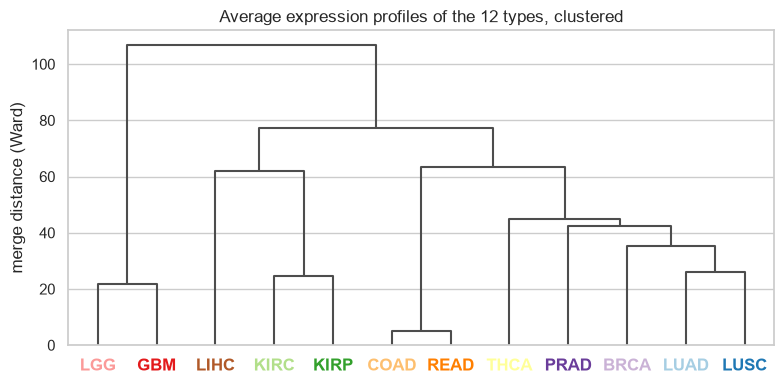

In [9]:
centroids = pd.DataFrame(P).groupby(y).mean().loc[ORDER]
tree = linkage(centroids.to_numpy(), method="ward")
fig, ax = plt.subplots(figsize=(8, 4))
dendrogram(tree, labels=centroids.index.tolist(), ax=ax, color_threshold=0, above_threshold_color="0.3")
for lbl in ax.get_xticklabels():
    lbl.set_color(PALETTE[lbl.get_text()])
    lbl.set_fontweight("bold")
ax.set(ylabel="merge distance (Ward)", title="Average expression profiles of the 12 types, clustered")
ax.grid(axis="x", visible=False)
fig.tight_layout()
fig.savefig(FIGURES / "11_type_dendrogram.png", dpi=150)
plt.show()

* **Colon and rectum join almost immediately** (merge distance about 5, against 22–26 for the other related pairs).
  By expression they are one group.
* **The brain tumours form the first split.** That fits their biology: gliomas grow from **glial cells** (support cells
  of the nervous system), while the other ten types are **carcinomas**, cancers of epithelial tissue (the lining of
  organs and glands).
* The lung pair, the kidney pair and the brain pair each join at a similar, low height, before any unrelated organs.

## 5 · Two traps

**Trap 1: k-means without restarts.** With a single random start (`n_init=1`), the result depends on luck:

In [10]:
single = [adjusted_rand_score(y, KMeans(12, n_init=1, random_state=s).fit_predict(P)) for s in range(20)]
print(
    f"k = 12, n_init=1, 20 seeds: ARI from {min(single):.2f} to {max(single):.2f} (median {np.median(single):.2f})"
)

k = 12, n_init=1, 20 seeds: ARI from 0.71 to 0.83 (median 0.77)


**Trap 2: clustering a UMAP map, then quoting its silhouette.** UMAP squeezes groups into tight islands, so a
silhouette computed *on the map* looks excellent. The same clusters, scored in the real (50-PC) space, look ordinary.

In [11]:
U = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=SEED).fit_transform(P)
on_map = KMeans(12, n_init=20, random_state=SEED).fit_predict(U)
on_pcs = found[12]
pd.DataFrame(
    {
        "k-means on 50 PCs": {
            "ARI": adjusted_rand_score(y, on_pcs),
            "silhouette (map)": silhouette_score(U, on_pcs),
            "silhouette (50 PCs)": silhouette_score(P, on_pcs),
        },
        "k-means on UMAP map": {
            "ARI": adjusted_rand_score(y, on_map),
            "silhouette (map)": silhouette_score(U, on_map),
            "silhouette (50 PCs)": silhouette_score(P, on_map),
        },
    }
).T.round(3)

,ARI,silhouette (map),silhouette (50 PCs)
k-means on 50 PCs,0.824,0.768,0.407
k-means on UMAP map,0.829,0.749,0.341


* **Trap 1:** single-start k-means gives ARI anywhere from 0.71 to 0.83 depending on the seed. Always use several
  restarts (`n_init`), and report the seed.
* **Trap 2:** *any* clustering scored on the UMAP map gets a silhouette of about 0.75–0.77, roughly **double** its
  value in the 50-PC space (0.34–0.41). UMAP packs points into tight islands, so a map-based silhouette mostly
  measures UMAP, not the data. Clustering *on* the map gives about the same ARI (0.83 vs 0.82), so it isn't wrong to
  do; it's wrong to quote its silhouette as evidence of clear clusters.

## Conclusions

1. **Unsupervised clustering rediscovers the cancer types well:** k-means reaches ARI 0.82 at k = 12, and **0.94**
   once colon and rectum are treated as one disease.
2. **k-means ≈ Ward > average ≈ complete linkage** on this data. Compact-cluster methods suit tissue-type structure.
3. **The silhouette chose 9 groups, not 12, and that wasn't a failure:** at k = 9 the clusters are **organs** (brain,
   kidney, colorectum merged; lung split). Label-free scores find the strongest structure, which is not necessarily
   the categories a clinician uses. In a discovery project, *k* must be justified biologically, not by one score.
4. **Report what you can't explain.** A small mixed cluster had no consistent marker signature; I leave it open
   rather than invent a story.
5. **Two traps:** single-start k-means (ARI 0.71–0.83 by seed alone) and silhouettes computed on UMAP maps (inflated
   about 2×).

---
*Data: TCGA pan-cancer RNA-seq (via UCSC Xena, as distributed with the course's gene-expression project), in
git-ignored `data/raw/gene_expression/`. TCGA data are open access under the NIH GDC data-use policy. Runs in about
a minute.*